# 06 Tabular baselines (Model Family A) and anomaly detectors (Family B)
Chronological split: first 60% of days train, next 20% validation, last 20% test. No random split, no resampling before splitting; imbalance via class weights; thresholds chosen on validation only.

In [1]:
import sys, pathlib, json, warnings; warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
def table(name):
    p = ROOT / 'reports' / 'tables' / name
    return pd.read_csv(p) if p.exists() else None

{'txn_only': 0.2621144934830046, '+behaviour': 0.5223947305338035, '+beneficiary/device': 0.917533269786435, '+graph': 0.9771830611614704}


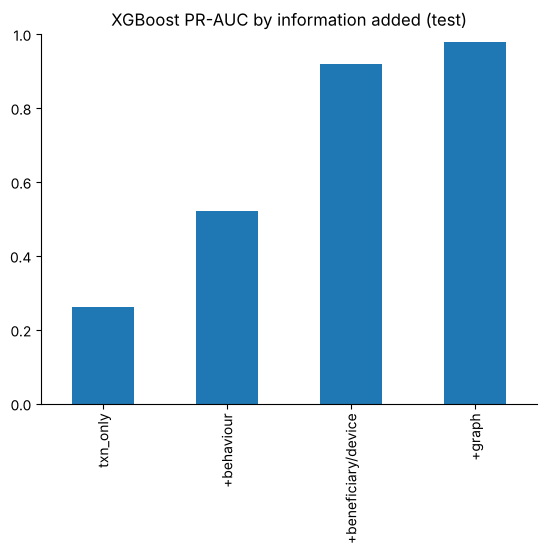

In [2]:
import json, time
from sklearn.metrics import average_precision_score
from presage.data.loaders import load_sim, load_features
from presage.evaluation.metrics import temporal_split
from presage.models.tabular import make_supervised
df, acc = load_sim(); X = load_features(); g = json.load(open(ROOT/'data/processed/sim_v1_feature_groups.json'))
cust = df.src_is_customer.values==1; tr0,va0,te0 = temporal_split(df.day.values); tr, te = tr0&cust, te0&cust; y = df.is_app_fraud.values
sets = {'txn_only': g['txn'], '+behaviour': g['txn']+g['behaviour'], '+beneficiary/device': g['txn']+g['behaviour']+g['beneficiary']+g['device'], '+graph': g['txn']+g['behaviour']+g['beneficiary']+g['device']+g['graph']}
res = {}
for name, cols in sets.items():
    m = make_supervised('xgboost', 50).fit(np.nan_to_num(X.loc[tr, cols].values), y[tr]); res[name] = average_precision_score(y[te], m.predict_proba(np.nan_to_num(X.loc[te, cols].values))[:,1])
pd.Series(res).plot(kind='bar', title='XGBoost PR-AUC by information added (test)', ylim=(0,1)); print(res)

Each information source lifts detection; transaction-only learning is far from sufficient for APP. Full results for five supervised models and five anomaly detectors (with bootstrap CIs):

In [3]:
b = table('baselines.csv'); b[['feature_set','model','pr_auc','pr_auc_lo','pr_auc_hi','roc_auc','recall','precision','f2','mcc','fpr','latency_ms']].round(3)

,feature_set,model,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,recall,precision,f2,mcc,fpr,latency_ms
0,txn_only,logreg,0.142,0.110,0.182,0.921,0.297,0.168,0.257,0.218,0.007,0.000
1,txn_only,random_forest,0.249,0.190,0.305,0.886,0.461,0.308,0.419,0.373,0.005,0.005
2,txn_only,xgboost,0.262,0.200,0.328,0.936,0.432,0.313,0.402,0.364,0.005,0.003
3,txn_only,lightgbm,0.231,0.169,0.284,0.935,0.377,0.266,0.348,0.313,0.005,0.005
4,txn_only,catboost,0.252,0.185,0.323,0.915,0.374,0.342,0.367,0.355,0.004,0.001
5,txn+behaviour,logreg,0.155,0.114,0.205,0.883,0.277,0.226,0.265,0.246,0.005,0.001
6,txn+behaviour,random_forest,0.489,0.408,0.568,0.928,0.516,0.500,0.513,0.506,0.003,0.006
7,txn+behaviour,xgboost,0.522,0.433,0.593,0.948,0.542,0.488,0.530,0.512,0.003,0.003
8,txn+behaviour,lightgbm,0.476,0.397,0.551,0.944,0.435,0.542,0.453,0.484,0.002,0.007
9,txn+behaviour,catboost,0.534,0.455,0.601,0.942,0.516,0.578,0.527,0.544,0.002,0.001


Anomaly detectors (Isolation Forest, LOF, One-Class SVM, autoencoder, VAE) reach only 0.05-0.41 PR-AUC: unsupervised scores flag unusual payments, but APP scams are authorised and often unremarkable individually. They are best used as a complement for unseen fraud behaviour, not a replacement.

**LightGBM note.** An early class-weighted configuration diverged on training (PR-AUC 0.004) and was removed; the final unweighted configuration is less stable than XGBoost/CatBoost on some feature sets (see table). We report it as measured.